## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Giovanni Alejandro Castillo Buitrago" # @param {"type":"string"}
carnet = 1000115755 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Un equipo de electrónica está diseñando un prototipo sobre una **protoboard** de 30 columnas (1 a 30) y 10 filas (A a J). Sobre ella hay siete componentes que deben quedar conectados entre sí: Fuente de alimentación (F, A3), LED (L, C8), Sensor (S, B16), Pulsador (P, D24), Buzzer (B, H6), Potenciómetro (R, I15) y Microcontrolador (M, G25).

El problema es que se quiere usar **la menor cantidad posible de cable**. Para resolverlo se modela la protoboard como un **grafo**: cada componente es un vértice, cada posible cable es una arista y su longitud es el peso de la arista, calculada con la distancia

$$d = |\text{col}_1 - \text{col}_2| + |\text{fila}_1 - \text{fila}_2|$$

(con A = 1, B = 2, ..., J = 10). Luego se construye un **Árbol de Expansión Mínima (MST)** con el **algoritmo de Kruskal**, implementado manualmente, que conecta los 7 componentes con exactamente 6 cables y la menor longitud total posible.

Finalmente se mueve el Buzzer de H6 a J20, se recalcula el MST y se compara la longitud total de cable antes y después del cambio.


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.


### Requerimientos funcionales
- **RF1.** Dibujar la protoboard (columnas 1 a 30, filas A a J) y ubicar los siete componentes en sus posiciones, con su identificador.
- **RF2.** Construir el grafo: cada componente es un vértice y cada pareja de componentes es una arista.
- **RF3.** Calcular automáticamente la distancia entre cada pareja con `|col1 - col2| + |fila1 - fila2|`, sin escribir pesos a mano.
- **RF4.** Mostrar gráficamente todas las posibles conexiones, cada una con su peso.
- **RF5.** Implementar manualmente el algoritmo de Kruskal: ordenar las aristas por peso, elegir las menores y evitar ciclos hasta conectar todos los componentes.
- **RF6.** Mostrar el resultado del MST: los componentes, los cables elegidos, la longitud de cada uno y la longitud total (con 7 componentes, exactamente 6 cables).
- **RF7.** Dibujar la protoboard únicamente con los cables del MST.
- **RF8.** Mover el Buzzer de H6 a J20, recalcular automáticamente el grafo y el MST, mostrar ambas longitudes totales e indicar si el cable aumentó o disminuyó.
- **RF9.** Permitir mover cualquier otro componente a una posición libre y recalcular el MST.

### Requerimientos no funcionales
- **RNF1. Corrección:** el MST debe tener n - 1 aristas, no tener ciclos y ser de longitud mínima (se verifica con un algoritmo independiente, Prim, en los tests).
- **RNF2. Implementación manual:** Kruskal y la detección de ciclos (Union-Find) se programan desde cero, sin librerías que calculen el MST.
- **RNF3. Visualización:** las gráficas se generan desde el propio notebook con `matplotlib`.
- **RNF4. Robustez:** valida posiciones (letra A-J y columna 1-30), posiciones ocupadas y componentes inexistentes sin que el programa se caiga.
- **RNF5. Claridad:** código modular, con funciones pequeñas, nombres descriptivos y comentarios.
- **RNF6. Ejecutable:** todo corre desde un único `main()` con menú en Python 3.


## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.

**HU1 – Ver la protoboard**
*Como* diseñador del prototipo, *quiero* ver la protoboard con mis siete componentes ubicados, *para* tener claro dónde está cada uno.
**Criterios de aceptación:**
- Se ven las columnas 1 a 30 y las filas A a J.
- Cada componente aparece en su posición con su identificador (F, L, S, P, B, R, M).

**HU2 – Ver las posibles conexiones**
*Como* diseñador, *quiero* ver todas las conexiones posibles con su longitud, *para* conocer cuánto cable costaría cada una.
**Criterios de aceptación:**
- Se calculan 21 conexiones (7 componentes → n(n-1)/2).
- Cada conexión muestra su peso, calculado automáticamente con la distancia de Manhattan.

**HU3 – Obtener el cableado mínimo**
*Como* diseñador, *quiero* que el programa encuentre cómo conectar todos los componentes con la menor cantidad de cable, *para* ahorrar material.
**Criterios de aceptación:**
- Se usa el algoritmo de Kruskal implementado manualmente.
- El resultado tiene exactamente 6 cables y no forma ciclos.
- Se muestra cada cable con su longitud y la longitud total.

**HU4 – Comparar con el cableado final**
*Como* diseñador, *quiero* ver la protoboard solo con los cables elegidos, *para* comparar la distribución original con el cableado obtenido.
**Criterios de aceptación:**
- Se dibujan únicamente las conexiones del MST, con su longitud.
- La longitud total aparece en el gráfico y en el resultado.

**HU5 – Mover un componente**
*Como* encargado del montaje, *quiero* mover un componente (por ejemplo el Buzzer de H6 a J20), *para* ver cómo cambia el cableado necesario.
**Criterios de aceptación:**
- El grafo y el MST se recalculan automáticamente con la nueva posición.
- Se muestran la longitud total original y la nueva, y se indica si el cable aumentó o disminuyó.
- Si la posición es inválida o está ocupada, se informa el error sin cerrar el programa.


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general


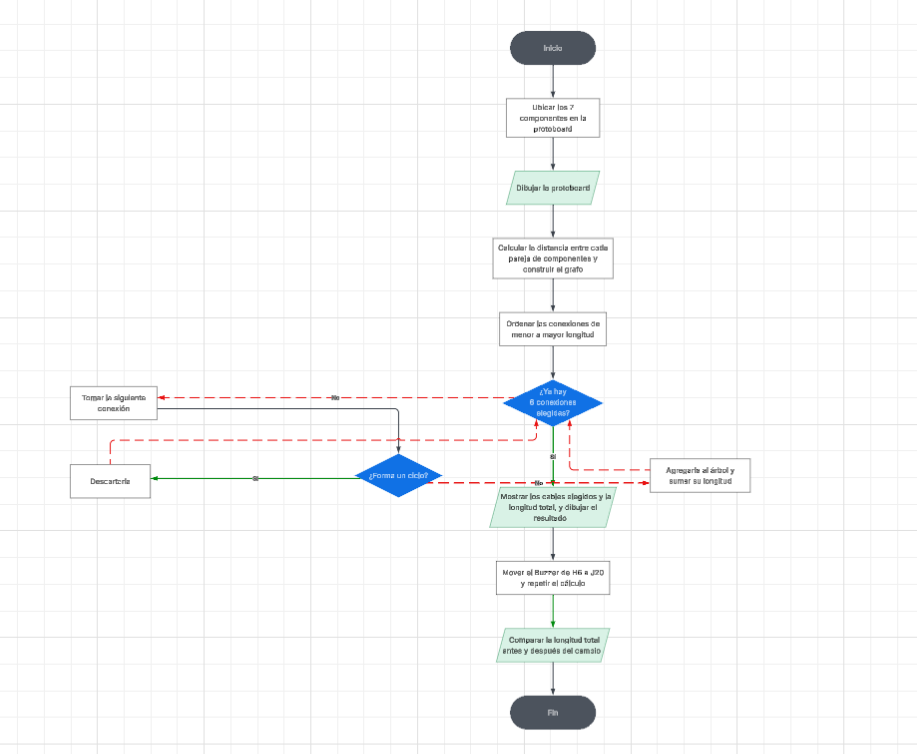

Adjunta imagen y descríbelo claramente.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

### Justificación
Sea **n** el número de componentes (vértices) y **E = n(n-1)/2** el número de conexiones posibles (aristas), porque se genera una arista por cada pareja. Kruskal hace tres cosas:

1. **Construir las aristas:** se calcula la distancia de cada pareja → E pasos, es decir O(n²).
2. **Ordenarlas** de menor a mayor peso → O(E log E).
3. **Recorrerlas** eligiendo las que no forman ciclo, con Union-Find (`find` con compresión de caminos y `union` por rango, casi constante, α(n)) → entre n - 1 y E aristas revisadas, cada una con costo casi constante.

Como E = n(n-1)/2 ≈ n²/2, se cumple log E = O(log n), así que el costo total queda dominado por el ordenamiento: **O(n² log n)**.

### Función T[n]
Contando operaciones elementales:

$$T(n) = \underbrace{\frac{n(n-1)}{2}}_{\text{crear aristas}} + \underbrace{E \log_2 E}_{\text{ordenar}} + \underbrace{k \cdot \alpha(n)}_{\text{recorrer con Union-Find}}$$

donde *k* es el número de aristas revisadas en el ciclo principal, con **n - 1 ≤ k ≤ E**.

| Caso | Situación | Aristas revisadas (k) | T(n) | Orden |
|---|---|---|---|---|
| **Mejor** | Las n - 1 aristas más livianas ya forman el MST (por ejemplo, componentes alineados) | n - 1 | ≈ n²/2 + E log E + (n-1) | O(n² log n) |
| **Promedio** | Posiciones aleatorias | entre n - 1 y E (medido) | ≈ n²/2 + E log E + k | O(n² log n) |
| **Peor** | Hace falta revisar todas las aristas hasta la última | E = n(n-1)/2 | ≈ n²/2 + E log E + E | O(n² log n) |

Para el caso del laboratorio, n = 7: E = 21 aristas, y Kruskal revisa solo 8 antes de completar las 6 conexiones del MST.

**Conclusión:** la diferencia entre mejor y peor caso está solo en cuántas aristas se revisan en el ciclo principal (de n - 1 a n(n-1)/2). Como crear y ordenar todas las aristas siempre se hace, el orden de crecimiento total es O(n² log n) en todos los casos, aunque el mejor caso hace mucho menos trabajo en el ciclo. El espacio es O(n²) por guardar las aristas.

### Gráfica de mejor y peor caso
La gráfica se genera desde el menú (opción 9) de la celda de código de la sección 6. Muestra cuántas aristas revisa el ciclo principal de Kruskal al crecer el número de componentes: el **mejor caso** (componentes alineados) crece linealmente como n - 1, el **caso promedio** (posiciones aleatorias, 20 pruebas por tamaño) queda entre ambos y el **peor caso** crece cuadráticamente como n(n-1)/2.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.

Implementación completa en **una sola celda** con un único `main()`. Al ejecutarla se abre un **menú** para elegir qué hacer: ejecutar todo el laboratorio de una vez (Puntos 1 a 6), correr cada punto por separado, mover otro componente y recalcular el MST, restablecer la distribución, ejecutar los tests o ver la gráfica de complejidad.

La salida que se ve debajo es una sesión real del programa: opción 1 (todo el laboratorio, con las gráficas de la protoboard inicial, todas las conexiones, el MST y la comparación tras mover el Buzzer), opción 8 (tests) y opción 9 (gráfica de complejidad).


CONECTANDO UNA PROTOBOARD CON LA MENOR CANTIDAD DE CABLE

MENÚ
1) Ejecutar todo (Puntos 1 a 6)
2) Punto 1: protoboard con los componentes
3) Puntos 2 y 3: distancias y todas las conexiones
4) Puntos 4 y 5: Kruskal y conexiones mínimas
5) Punto 6: mover el Buzzer de H6 a J20 y comparar
6) Mover otro componente (tú eliges) y recalcular el MST
7) Restablecer la distribución inicial
8) Ejecutar tests
9) Gráfica de mejor y peor caso
0) Salir
PUNTO 1. PROTOBOARD INICIAL
Id  Componente                Posición  (col, fila)
F   Fuente de alimentación    A3        (3, 1)
L   LED                       C8        (8, 3)
S   Sensor                    B16       (16, 2)
P   Pulsador                  D24       (24, 4)
B   Buzzer                    H6        (6, 8)
R   Potenciómetro             I15       (15, 9)
M   Microcontrolador          G25       (25, 7)


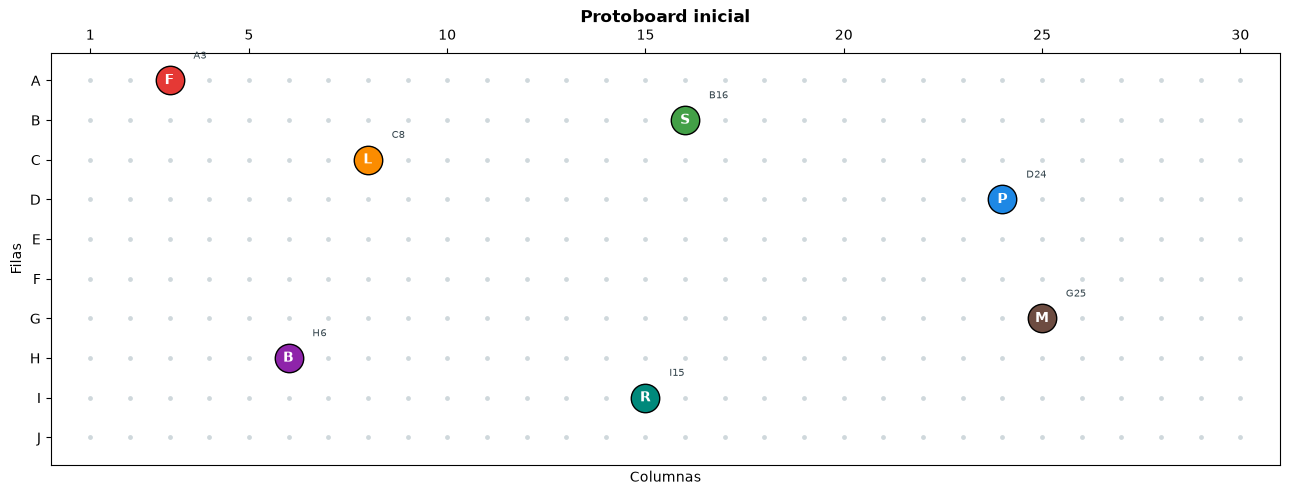


PUNTOS 2 y 3. DISTANCIAS ENTRE COMPONENTES (todas las conexiones)
F --------  7 -------- L    (|3-8| + |1-3| = 5 + 2)
F -------- 14 -------- S    (|3-16| + |1-2| = 13 + 1)
F -------- 24 -------- P    (|3-24| + |1-4| = 21 + 3)
F -------- 10 -------- B    (|3-6| + |1-8| = 3 + 7)
F -------- 20 -------- R    (|3-15| + |1-9| = 12 + 8)
F -------- 28 -------- M    (|3-25| + |1-7| = 22 + 6)
L --------  9 -------- S    (|8-16| + |3-2| = 8 + 1)
L -------- 17 -------- P    (|8-24| + |3-4| = 16 + 1)
L --------  7 -------- B    (|8-6| + |3-8| = 2 + 5)
L -------- 13 -------- R    (|8-15| + |3-9| = 7 + 6)
L -------- 21 -------- M    (|8-25| + |3-7| = 17 + 4)
S -------- 10 -------- P    (|16-24| + |2-4| = 8 + 2)
S -------- 16 -------- B    (|16-6| + |2-8| = 10 + 6)
S --------  8 -------- R    (|16-15| + |2-9| = 1 + 7)
S -------- 14 -------- M    (|16-25| + |2-7| = 9 + 5)
P -------- 22 -------- B    (|24-6| + |4-8| = 18 + 4)
P -------- 14 -------- R    (|24-15| + |4-9| = 9 + 5)
P --------  4 -------- 

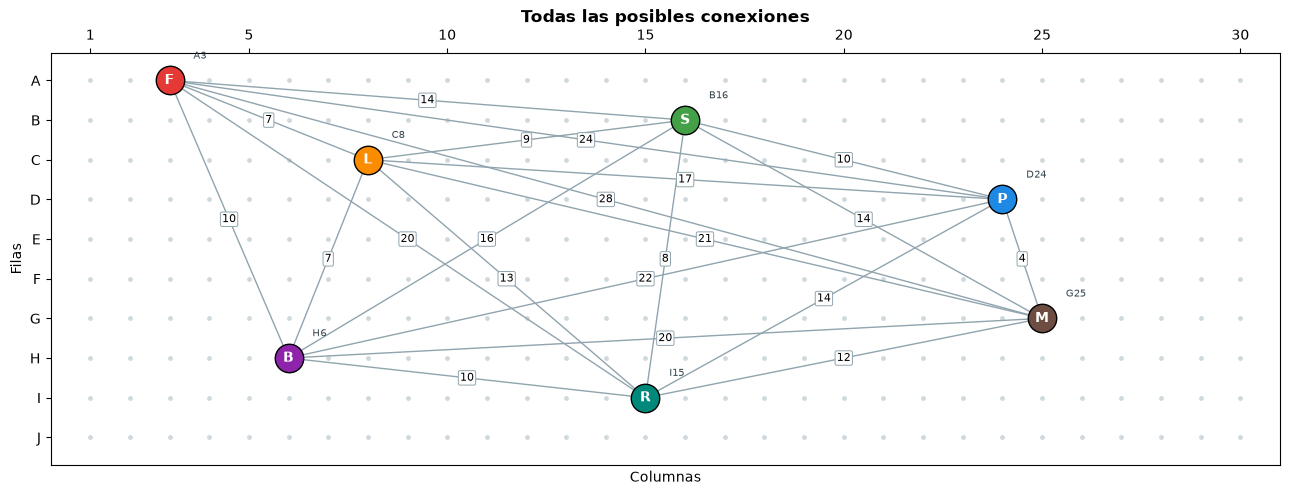


PUNTO 4. ALGORITMO DE KRUSKAL
Conexiones ordenadas de menor a mayor peso:
  P - M =  4  ->  ACEPTADA
  F - L =  7  ->  ACEPTADA
  L - B =  7  ->  ACEPTADA
  S - R =  8  ->  ACEPTADA
  L - S =  9  ->  ACEPTADA
  B - R = 10  ->  descartada (formaría un ciclo)
  F - B = 10  ->  descartada (formaría un ciclo)
  S - P = 10  ->  ACEPTADA

Conexiones revisadas: 8  |  Conexiones elegidas: 6 (n - 1 = 6)

========== RESULTADO ==========
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Longitud total de cable: 45 unidades


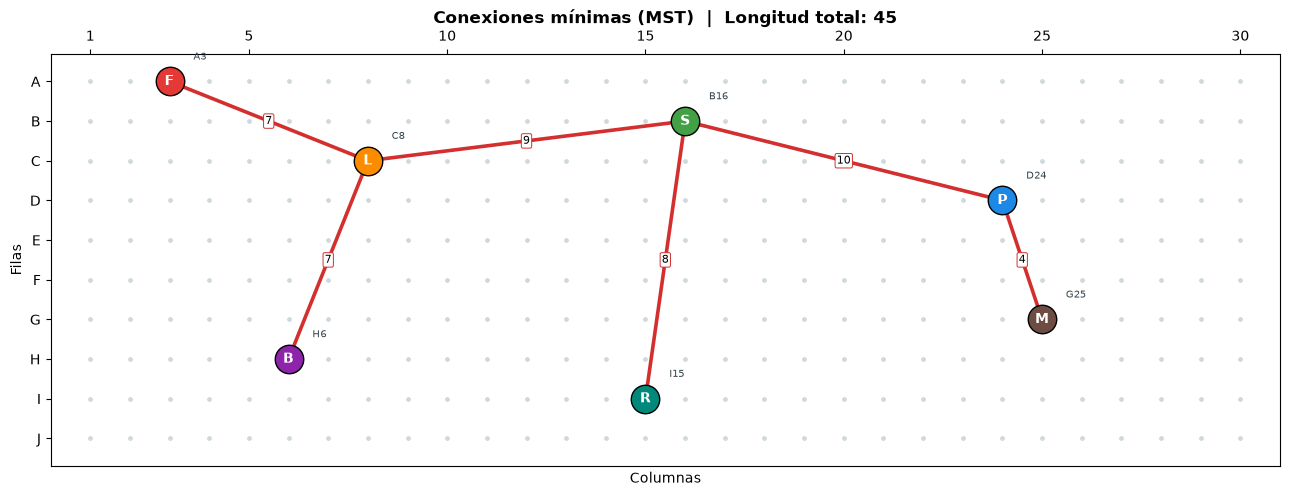


PUNTO 6. CAMBIO EN LA DISTRIBUCIÓN
Buzzer (B): H6 -> J20

MST original
Longitud total: 45
MST después del cambio
Longitud total: 42

Cables del MST después del cambio:
  Cable 1: P - M = 4
  Cable 2: B - R = 6
  Cable 3: F - L = 7
  Cable 4: B - M = 8
  Cable 5: S - R = 8
  Cable 6: L - S = 9

¿Aumentó o disminuyó el cable? DISMINUYÓ en 3 unidades (45 -> 42).


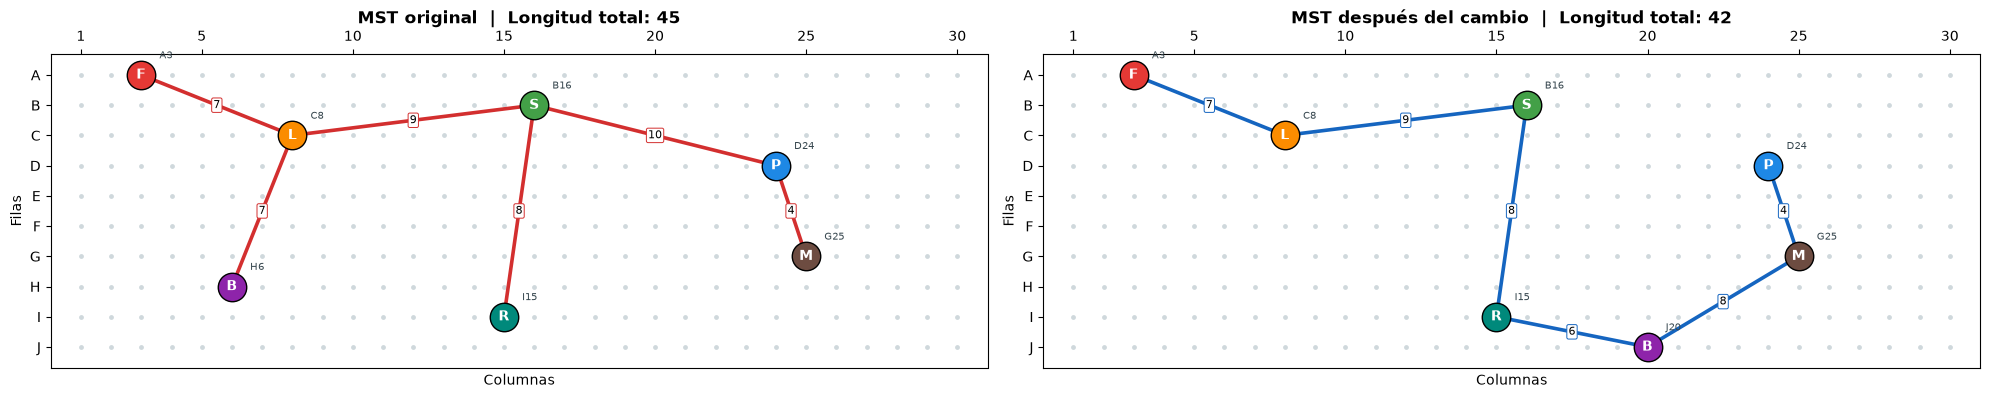


MENÚ
1) Ejecutar todo (Puntos 1 a 6)
2) Punto 1: protoboard con los componentes
3) Puntos 2 y 3: distancias y todas las conexiones
4) Puntos 4 y 5: Kruskal y conexiones mínimas
5) Punto 6: mover el Buzzer de H6 a J20 y comparar
6) Mover otro componente (tú eliges) y recalcular el MST
7) Restablecer la distribución inicial
8) Ejecutar tests
9) Gráfica de mejor y peor caso
0) Salir
✔ T1  Conversión de posiciones: A3 -> (3, 1), J30 -> (30, 10)
✔ T2  Posiciones inválidas lanzan ValueError (K3, A0, A31, 3A, vacío)
✔ T3  Distancia F-L = |3-8| + |1-3| = 7 (ejemplo del enunciado)
✔ T4  7 componentes generan 21 conexiones posibles, sin repetidas
✔ T5  El MST tiene exactamente n - 1 = 6 conexiones
✔ T6  El MST no tiene ciclos y conecta a los 7 componentes
✔ T7  Longitud total (45) coincide con un MST calculado con Prim (verificación independiente)
✔ T8  Las conexiones se procesan de menor a mayor peso
✔ T9  Mover el Buzzer H6 -> J20 actualiza la posición sin alterar la distribución original
✔ T

KeyboardInterrupt: Interrupted by user

In [ ]:

import random
import matplotlib.pyplot as plt

COLUMNAS = 30
FILAS = "ABCDEFGHIJ"                      # A = 1, B = 2, ..., J = 10

NOMBRES = {
    "F": "Fuente de alimentación",
    "L": "LED",
    "S": "Sensor",
    "P": "Pulsador",
    "B": "Buzzer",
    "R": "Potenciómetro",
    "M": "Microcontrolador",
}
ORDEN = ["F", "L", "S", "P", "B", "R", "M"]
POSICIONES_INICIALES = {
    "F": "A3", "L": "C8", "S": "B16", "P": "D24",
    "B": "H6", "R": "I15", "M": "G25",
}
COLORES = {
    "F": "#E53935", "L": "#FB8C00", "S": "#43A047", "P": "#1E88E5",
    "B": "#8E24AA", "R": "#00897B", "M": "#6D4C41",
}


def parsear_posicion(texto):
    """'A3' -> (columna=3, fila=1). Lanza ValueError si es inválida."""
    texto = texto.strip().upper()
    if len(texto) < 2 or texto[0] not in FILAS or not texto[1:].isdigit():
        raise ValueError(f"Posición inválida: '{texto}'. Use una letra A-J y una columna 1-30 (ej. A3).")
    columna = int(texto[1:])
    if not 1 <= columna <= COLUMNAS:
        raise ValueError(f"Columna fuera de rango: {columna}. Debe estar entre 1 y {COLUMNAS}.")
    return (columna, FILAS.index(texto[0]) + 1) 


def nombre_posicion(columna, fila):
    """(3, 1) -> 'A3'"""
    return f"{FILAS[fila - 1]}{columna}"


def distancia(a, b):
    """distancia = |columna1 - columna2| + |fila1 - fila2|"""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def construir_coordenadas(posiciones):
    """{'F': 'A3', ...} -> {'F': (3, 1), ...}"""
    return {c: parsear_posicion(p) for c, p in posiciones.items()}



def construir_aristas(coords):
    claves = list(coords.keys())
    aristas = []
    for i in range(len(claves)):
        for j in range(i + 1, len(claves)):
            u, v = claves[i], claves[j]
            aristas.append((distancia(coords[u], coords[v]), u, v))
    return aristas


class UnionFind:
    def __init__(self, elementos):
        self.padre = {e: e for e in elementos}
        self.rango = {e: 0 for e in elementos}

    def find(self, x):
        if self.padre[x] != x:
            self.padre[x] = self.find(self.padre[x])    
        return self.padre[x]

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                                  
        if self.rango[ra] < self.rango[rb]:
            ra, rb = rb, ra
        self.padre[rb] = ra
        if self.rango[ra] == self.rango[rb]:
            self.rango[ra] += 1
        return True



def kruskal(coords):
    """Devuelve (mst, total, revisadas, traza).
    mst: aristas elegidas | total: suma de pesos | revisadas: aristas examinadas
    traza: lista de (arista, aceptada) para poder explicar el algoritmo."""
    aristas = sorted(construir_aristas(coords))            
    uf = UnionFind(coords.keys())
    mst, traza, revisadas = [], [], 0
    for arista in aristas:                                 
        if len(mst) == len(coords) - 1:                    
            break
        revisadas += 1
        peso, u, v = arista
        if uf.union(u, v):                                 
            mst.append(arista)
            traza.append((arista, True))
        else:
            traza.append((arista, False))
    total = sum(p for p, _, _ in mst)
    return mst, total, revisadas, traza



def dibujar_protoboard(ax, coords, aristas=None, titulo="", color_arista="#546E7A", grosor=1.4):
    # agujeros de la protoboard
    huecos_x = [c for c in range(1, COLUMNAS + 1) for _ in FILAS]
    huecos_y = [f for _ in range(1, COLUMNAS + 1) for f in range(1, len(FILAS) + 1)]
    ax.scatter(huecos_x, huecos_y, s=6, color="#CFD8DC", zorder=1)

    # cables (con su longitud)
    if aristas:
        for peso, u, v in aristas:
            (x1, y1), (x2, y2) = coords[u], coords[v]
            ax.plot([x1, x2], [y1, y2], color=color_arista, lw=grosor, zorder=2)
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(peso), fontsize=8, ha="center", va="center",
                    zorder=4, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color_arista, lw=0.7))

  
    for c, (col, fila) in coords.items():
        ax.scatter([col], [fila], s=420, color=COLORES.get(c, "#455A64"), edgecolor="black", zorder=5)
        ax.text(col, fila, c, color="white", fontsize=10, weight="bold", ha="center", va="center", zorder=6)
        ax.text(col + 0.6, fila - 0.55, nombre_posicion(col, fila), fontsize=7, color="#37474F", zorder=6)

    ax.set_xlim(0, COLUMNAS + 1)
    ax.set_ylim(len(FILAS) + 0.7, 0.3)                    
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax.set_yticks(range(1, len(FILAS) + 1))
    ax.set_yticklabels(list(FILAS))
    ax.xaxis.tick_top()
    ax.set_xlabel("Columnas")
    ax.set_ylabel("Filas")
    ax.set_title(titulo, fontsize=12, weight="bold", pad=22)
    ax.set_aspect("equal")


def mostrar_figura(coords, aristas, titulo, color="#546E7A", grosor=1.4):
    fig, ax = plt.subplots(figsize=(13, 5.2))
    dibujar_protoboard(ax, coords, aristas, titulo, color, grosor)
    plt.tight_layout()
    plt.show()



def punto_1(posiciones):
    print("=" * 56)
    print("PUNTO 1. PROTOBOARD INICIAL")
    print("=" * 56)
    print(f"{'Id':<4}{'Componente':<26}{'Posición':<10}{'(col, fila)'}")
    coords = construir_coordenadas(posiciones)
    for c in posiciones:
        print(f"{c:<4}{NOMBRES.get(c, c):<26}{posiciones[c]:<10}{coords[c]}")
    mostrar_figura(coords, None, "Protoboard inicial")


def punto_2_y_3(posiciones):
    coords = construir_coordenadas(posiciones)
    aristas = construir_aristas(coords)
    print("=" * 56)
    print("PUNTOS 2 y 3. DISTANCIAS ENTRE COMPONENTES (todas las conexiones)")
    print("=" * 56)
    for peso, u, v in aristas:
        (c1, f1), (c2, f2) = coords[u], coords[v]
        print(f"{u} -------- {peso:>2} -------- {v}    "
              f"(|{c1}-{c2}| + |{f1}-{f2}| = {abs(c1 - c2)} + {abs(f1 - f2)})")
    print(f"\nTotal de conexiones posibles: {len(aristas)}  (= n(n-1)/2 con n = {len(coords)})")
    mostrar_figura(coords, aristas, "Todas las posibles conexiones", "#90A4AE", 1.0)


def punto_4_y_5(posiciones, titulo="Árbol de Expansión Mínima (Kruskal)", detalle=True):
    coords = construir_coordenadas(posiciones)
    mst, total, revisadas, traza = kruskal(coords)
    if detalle:
        print("=" * 56)
        print("PUNTO 4. ALGORITMO DE KRUSKAL")
        print("=" * 56)
        print("Conexiones ordenadas de menor a mayor peso:")
        for (peso, u, v), aceptada in traza:
            estado = "ACEPTADA" if aceptada else "descartada (formaría un ciclo)"
            print(f"  {u} - {v} = {peso:>2}  ->  {estado}")
        print(f"\nConexiones revisadas: {revisadas}  |  Conexiones elegidas: {len(mst)} (n - 1 = {len(coords) - 1})")
    print()
    print("========== RESULTADO ==========")
    for i, (peso, u, v) in enumerate(mst, start=1):
        print(f"Cable {i}: {u} - {v} = {peso}")
    print(f"Longitud total de cable: {total} unidades")
    mostrar_figura(coords, mst, f"{titulo}  |  Longitud total: {total}", "#D32F2F", 2.6)
    return mst, total


def cambiar_posicion(posiciones, componente, nueva_posicion):
    """Devuelve una copia de la distribución con el componente movido."""
    componente = componente.strip().upper()
    if componente not in posiciones:
        raise ValueError(f"El componente '{componente}' no existe.")
    nueva = parsear_posicion(nueva_posicion)
    for c, p in posiciones.items():
        if c != componente and parsear_posicion(p) == nueva:
            raise ValueError(f"La posición {nueva_posicion.upper()} ya está ocupada por {c}.")
    copia = dict(posiciones)
    copia[componente] = nueva_posicion.strip().upper()
    return copia


def punto_6(posiciones, componente="B", nueva="J20"):
    print("=" * 56)
    print("PUNTO 6. CAMBIO EN LA DISTRIBUCIÓN")
    print("=" * 56)
    antes = construir_coordenadas(posiciones)
    mst_a, total_a, _, _ = kruskal(antes)
    original = posiciones[componente]
    nuevas = cambiar_posicion(posiciones, componente, nueva)
    despues = construir_coordenadas(nuevas)
    mst_d, total_d, _, _ = kruskal(despues)

    print(f"{NOMBRES.get(componente, componente)} ({componente}): {original} -> {nueva.upper()}\n")
    print("MST original")
    print(f"Longitud total: {total_a}")
    print("MST después del cambio")
    print(f"Longitud total: {total_d}\n")
    print("Cables del MST después del cambio:")
    for i, (peso, u, v) in enumerate(mst_d, start=1):
        print(f"  Cable {i}: {u} - {v} = {peso}")

    diferencia = total_d - total_a
    if diferencia > 0:
        print(f"\n¿Aumentó o disminuyó el cable? AUMENTÓ en {diferencia} unidades ({total_a} -> {total_d}).")
    elif diferencia < 0:
        print(f"\n¿Aumentó o disminuyó el cable? DISMINUYÓ en {-diferencia} unidades ({total_a} -> {total_d}).")
    else:
        print(f"\n¿Aumentó o disminuyó el cable? Se mantuvo igual ({total_a} unidades).")

    fig, ejes = plt.subplots(1, 2, figsize=(20, 4.8))
    dibujar_protoboard(ejes[0], antes, mst_a, f"MST original  |  Longitud total: {total_a}", "#D32F2F", 2.6)
    dibujar_protoboard(ejes[1], despues, mst_d, f"MST después del cambio  |  Longitud total: {total_d}", "#1565C0", 2.6)
    plt.tight_layout()
    plt.show()
    return nuevas



def _prim_total(coords):
    """MST con Prim, solo para verificar que Kruskal da el mismo total."""
    claves = list(coords.keys())
    dentro = {claves[0]}
    total = 0
    while len(dentro) < len(claves):
        mejor = None
        for u in dentro:
            for v in claves:
                if v not in dentro:
                    d = distancia(coords[u], coords[v])
                    if mejor is None or d < mejor[0]:
                        mejor = (d, v)
        total += mejor[0]
        dentro.add(mejor[1])
    return total


def ejecutar_tests():
    assert parsear_posicion("A3") == (3, 1) and parsear_posicion("J30") == (30, 10)
    print("✔ T1  Conversión de posiciones: A3 -> (3, 1), J30 -> (30, 10)")

    for malo in ("K3", "A0", "A31", "3A", "", "A"):
        try:
            parsear_posicion(malo)
            assert False, f"debía fallar con '{malo}'"
        except ValueError:
            pass
    print("✔ T2  Posiciones inválidas lanzan ValueError (K3, A0, A31, 3A, vacío)")

    coords = construir_coordenadas(POSICIONES_INICIALES)
    assert distancia(coords["F"], coords["L"]) == 7
    print("✔ T3  Distancia F-L = |3-8| + |1-3| = 7 (ejemplo del enunciado)")

    aristas = construir_aristas(coords)
    assert len(aristas) == 21 and len({(u, v) for _, u, v in aristas}) == 21
    print("✔ T4  7 componentes generan 21 conexiones posibles, sin repetidas")

    mst, total, _, _ = kruskal(coords)
    assert len(mst) == 6
    print("✔ T5  El MST tiene exactamente n - 1 = 6 conexiones")

    uf = UnionFind(coords.keys())
    for _, u, v in mst:
        assert uf.union(u, v), "se formó un ciclo"
    assert len({uf.find(c) for c in coords}) == 1
    print("✔ T6  El MST no tiene ciclos y conecta a los 7 componentes")

    assert total == sum(p for p, _, _ in mst) == _prim_total(coords)
    print(f"✔ T7  Longitud total ({total}) coincide con un MST calculado con Prim (verificación independiente)")

    ordenados = [p for p, _, _ in sorted(aristas)]
    assert ordenados == sorted(ordenados)
    print("✔ T8  Las conexiones se procesan de menor a mayor peso")

    nuevas = cambiar_posicion(POSICIONES_INICIALES, "B", "J20")
    assert nuevas["B"] == "J20" and POSICIONES_INICIALES["B"] == "H6"
    print("✔ T9  Mover el Buzzer H6 -> J20 actualiza la posición sin alterar la distribución original")

    coords2 = construir_coordenadas(nuevas)
    mst2, total2, _, _ = kruskal(coords2)
    assert len(mst2) == 6 and total2 == _prim_total(coords2)
    print(f"✔ T10 Tras el cambio se recalcula el MST: 6 conexiones, total {total2} (coincide con Prim)")

    try:
        cambiar_posicion(POSICIONES_INICIALES, "B", "A3")
        assert False, "debía rechazar una posición ocupada"
    except ValueError:
        pass
    try:
        cambiar_posicion(POSICIONES_INICIALES, "Z", "A1")
        assert False, "debía rechazar un componente inexistente"
    except ValueError:
        pass
    print("✔ T11 Se rechaza mover a una posición ocupada o mover un componente que no existe")

    linea = {i: (i + 1, 1) for i in range(5)}            
    mst3, total3, _, _ = kruskal(linea)
    assert len(mst3) == 4 and total3 == 4
    print("✔ T12 Caso simple: 5 puntos alineados -> 4 cables de longitud 1 (total 4)")

    triangulo = {"A": (1, 1), "B": (3, 1), "C": (2, 2)}
    mst4, total4, _, traza4 = kruskal(triangulo)
    assert len(mst4) == 2 and total4 == 4
    print("✔ T13 Triángulo: con 3 puntos se eligen 2 cables y se evita el ciclo (total 4)")

    uno = {"X": (5, 5)}
    mst5, total5, _, _ = kruskal(uno)
    assert mst5 == [] and total5 == 0
    print("✔ T14 Un solo componente: MST vacío, longitud 0")
    print("\nTodos los tests pasaron correctamente.")



def graficar_complejidad():
    random.seed(7)
    tamanos = list(range(4, 61, 4))
    mejor, promedio, peor = [], [], []
    for n in tamanos:
       
        _, _, rev, _ = kruskal({i: (i + 1, 1) for i in range(n)})
        mejor.append(rev)
       
        celdas = [(c, f) for c in range(1, COLUMNAS + 1) for f in range(1, len(FILAS) + 1)]
        suma = 0
        for _ in range(20):
            puntos = random.sample(celdas, n)
            _, _, rev, _ = kruskal({i: puntos[i] for i in range(n)})
            suma += rev
        promedio.append(suma / 20)
       
        peor.append(n * (n - 1) // 2)

    plt.figure(figsize=(8.5, 5))
    plt.plot(tamanos, peor, "o--", color="tab:red", markersize=4, label="Peor caso: n(n-1)/2 aristas")
    plt.plot(tamanos, promedio, "^-", color="tab:orange", markersize=4, label="Caso promedio (medido)")
    plt.plot(tamanos, mejor, "s-", color="tab:green", markersize=4, label="Mejor caso: n-1 aristas (medido)")
    plt.title("Kruskal: aristas revisadas según el número de componentes")
    plt.xlabel("n (componentes)")
    plt.ylabel("Aristas revisadas en el ciclo principal")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


def ejecutar_todo():
    posiciones = dict(POSICIONES_INICIALES)
    punto_1(posiciones)
    print()
    punto_2_y_3(posiciones)
    print()
    punto_4_y_5(posiciones, "Conexiones mínimas (MST)")
    print()
    punto_6(posiciones, "B", "J20")


def leer_entero(mensaje):
    while True:
        try:
            return int(input(mensaje))
        except ValueError:
            print("Entrada inválida. Ingrese un número entero.")



def main():
    posiciones = dict(POSICIONES_INICIALES)            
    print("CONECTANDO UNA PROTOBOARD CON LA MENOR CANTIDAD DE CABLE")

    while True:
        print("\n" + "=" * 56)
        print("MENÚ")
        print("=" * 56)
        print("1) Ejecutar todo (Puntos 1 a 6)")
        print("2) Punto 1: protoboard con los componentes")
        print("3) Puntos 2 y 3: distancias y todas las conexiones")
        print("4) Puntos 4 y 5: Kruskal y conexiones mínimas")
        print("5) Punto 6: mover el Buzzer de H6 a J20 y comparar")
        print("6) Mover otro componente (tú eliges) y recalcular el MST")
        print("7) Restablecer la distribución inicial")
        print("8) Ejecutar tests")
        print("9) Gráfica de mejor y peor caso")
        print("0) Salir")
        opcion = leer_entero("Opción: ")

        if opcion == 1:
            ejecutar_todo()
        elif opcion == 2:
            punto_1(posiciones)
        elif opcion == 3:
            punto_2_y_3(posiciones)
        elif opcion == 4:
            punto_4_y_5(posiciones)
        elif opcion == 5:
            punto_6(dict(POSICIONES_INICIALES), "B", "J20")
        elif opcion == 6:
            print("Distribución actual: " + ", ".join(f"{c}={posiciones[c]}" for c in ORDEN))
            componente = input("Componente a mover (F, L, S, P, B, R, M): ").strip().upper()
            nueva = input("Nueva posición (ej. J20): ").strip().upper()
            try:
                total_antes = kruskal(construir_coordenadas(posiciones))[1]
                posiciones = cambiar_posicion(posiciones, componente, nueva)
                _, total_despues = punto_4_y_5(posiciones, f"MST con {componente} en {nueva}", detalle=False)
                print(f"\nLongitud antes: {total_antes}  |  después: {total_despues}")
            except ValueError as error:
                print(f"Error: {error}")
        elif opcion == 7:
            posiciones = dict(POSICIONES_INICIALES)
            print("Distribución inicial restablecida.")
        elif opcion == 8:
            ejecutar_tests()
        elif opcion == 9:
            graficar_complejidad()
        elif opcion == 0:
            print("Hasta pronto.")
            break
        else:
            print("Opción no válida.")


if __name__ == "__main__":
    main()




## 7) Tests aplicados **[15 pts]**

Los tests están en la misma celda (función `ejecutar_tests()`, opción 8 del menú) y usan `assert`; se ven en la salida de la celda de la sección 6. Cobertura:

| # | Prueba | Resultado esperado |
|---|---|---|
| T1 | Conversión de posiciones | A3 → (3, 1), J30 → (30, 10) |
| T2 | Posiciones inválidas (K3, A0, A31, 3A, vacío) | Lanzan `ValueError` |
| T3 | Distancia F-L (ejemplo del enunciado) | 7 |
| T4 | Aristas con 7 componentes | 21, sin repetidas |
| T5 | Tamaño del MST | Exactamente 6 conexiones |
| T6 | Ciclos y conectividad | Sin ciclos y los 7 componentes conectados |
| T7 | Longitud mínima | Coincide con un MST calculado con Prim |
| T8 | Orden de procesamiento | De menor a mayor peso |
| T9 | Mover el Buzzer H6 → J20 | Actualiza la posición y no altera la distribución original |
| T10 | MST tras el cambio | 6 conexiones y longitud mínima (coincide con Prim) |
| T11 | Posición ocupada o componente inexistente | Se rechaza con `ValueError` |
| T12 | 5 puntos alineados | 4 cables de longitud 1, total 4 |
| T13 | Triángulo de 3 puntos | 2 cables, se evita el ciclo, total 4 |
| T14 | Un solo componente | MST vacío, longitud 0 |

Los resultados del laboratorio (MST original de **45** unidades y MST tras el cambio de **42** unidades) se ven en la salida de la opción 1.
